# 호출 수·비용·종료 조건 비교

**이 노트북에서 할 일**

1. 같은 문의 하나를 서브에이전트·핸드오프·라우터 세 구조에 보내고, 구조마다 모델 요청 수와 토큰을 셉니다.
2. 실행 한도와 호출 한도로 멈추는 실행을 실제로 만들어, 한도로 끝난 모양을 봅니다.
3. 필요한 결과가 다 모였는지 보는 완료 조건을 코드로 적고, 네 실행에 대어 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 3·4·5·7절에서 모델을 부릅니다.
노트북 밖에서 먼저 본 대로라면 모델 요청은 노트북 한 번에 11번입니다.
4절에서 서비스가 거절하는 요청 하나는 이 수에 넣지 않았습니다.
요금표로 어림한 예상 비용은 0.005달러 아래이고, 청구 금액이 아닙니다.

모델이 맡기는 모양·넘기는 수·고르는 분야와 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

읽거나 쓰는 파일은 없고, 4절의 체크포인트는 프로그램 메모리에만 둡니다.
앞 절과 앞 챕터에서 배운 함수 여섯은 도구 파일 `delegation_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 pydantic 2.13.5, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절과 8절을 읽습니다.
같은 문의로 두 구조를 실행하고, 완료 조건을 적는 자리입니다.
5절은 03절 라우터를 다시 만드는 자리이고, 6~7절은 요청 수 표와 한도 장면입니다.
이 세 절은 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch26-delegation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 같은 문의 글 하나 대출 연장과 토요일 운영 시간에서 화살표 셋이 나란한 파란 상자 셋으로 갑니다. 왼쪽 상자에는 서브에이전트, 중앙 에이전트가 도구로 맡기고 답을 받음, 중앙 = 도구를 요청한 응답 수 + 1, 전문 = 부른 횟수라고 적혀 있습니다. 가운데 상자에는 핸드오프, 안내 담당이 넘기기 도구로 넘김, 넘긴 담당 1 + 받은 담당 1이 적혀 있습니다. 오른쪽 상자에는 라우터, 분류 모델이 고르고 Send로 함께 보냄, 분류 1 + 고른 분야 수가 적혀 있습니다. 세 상자에서 화살표가 맨 아래 회색 상자 전문 에이전트 셋 desk_agents 세 구조가 함께 씀 도구 없음으로 모이는 그림](attachment:04-1-세-구조의-요청-셈.png)

위에서 아래로 읽습니다.
파란 상자 셋은 우리가 적은 세 구조이고, 상자 아래쪽 줄이 01~03절에서 정한 요청 수 셈입니다.
왼쪽 상자가 노트북 3절, 가운데가 4절, 오른쪽이 5절의 구조입니다.
맨 아래 회색 상자는 세 구조가 함께 쓴 전문 에이전트 셋입니다.
이 그림에는 이번 실행의 요청 수를 넣지 않았습니다.
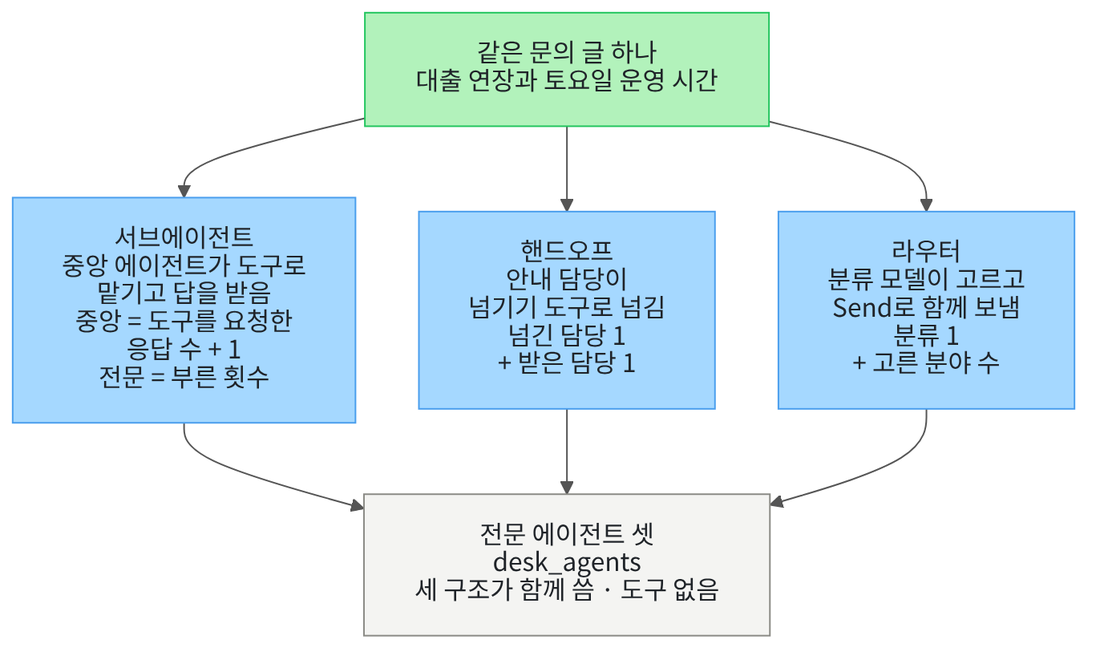

## 1. 준비

이 절에서는 01~03절의 세 구조에 같은 문의 하나를 보내, 호출 수와 비용과 종료 조건을 견줍니다.
절 제목의 종료 조건은 이 절에서 두 가지로 나눠 봅니다.
하나는 Ch 17 03절의 정지 조건으로, 실행이 멈추는 까닭입니다.
다른 하나는 이 절이 새로 적는 완료 조건으로, 일이 끝났는지 보는 기준입니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("pydantic:", version("pydantic"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
pydantic: 2.13.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `pydantic: 2.13.5`가 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판이고, 03절과 같은 다섯 패키지입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
실행 한도를 넘을 때 나는 오류 `GraphRecursionError`는 Ch 20 03절에서 썼습니다.
호출 한도 `ModelCallLimitMiddleware`는 Ch 22 04절, 체크포인터 `InMemorySaver`는 Ch 23 01절에서 썼습니다.
오류 이름 `ModelInvalidRequestError`는 이 절에서 처음 쓰고, 뜻은 4절에서 풉니다.

앞 절들은 `Annotated`·`Literal`을 typing에서, `TypedDict`를 typing_extensions에서 가져왔습니다.
패키지 typing_extensions는 typing과 같은 이름도 함께 내놓아, 이 절은 한 줄로 가져옵니다.

In [2]:
# 상태 형식(Ch 13 01·02절)·오류 이름·체크포인터(Ch 23 01절)·그래프와 Command(Ch 13 06절) 이름을 가져옵니다
import operator
from typing_extensions import Annotated, Literal, TypedDict
from langchain_core.exceptions import ModelInvalidRequestError
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.errors import GraphRecursionError
from langgraph.graph import END, START, StateGraph, add_messages
from langgraph.types import Command
# 양식 클래스(Ch 21 02절)·에이전트와 호출 한도(Ch 21 01절·Ch 22 04절)·모델·메시지·도구 이름을 가져옵니다
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import AnyMessage, HumanMessage, ToolMessage
from langchain.tools import ToolRuntime, tool
# 앞 절과 앞 챕터에서 배운 함수 여섯은 도구 파일에서 가져옵니다
from delegation_tools import estimate_cost, message_kinds, send_to_desks, sum_usage, usage_with_specialists, writer_names

print("도구 파일에서 가져온 함수:", "estimate_cost, message_kinds, send_to_desks, sum_usage, usage_with_specialists, writer_names")

도구 파일에서 가져온 함수: estimate_cost, message_kinds, send_to_desks, sum_usage, usage_with_specialists, writer_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, message_kinds, send_to_desks, sum_usage, usage_with_specialists, writer_names`가 보입니다.
이 가운데 둘은 앞 챕터 함수이고, 넷은 01~03절에서 처음 가르친 함수입니다.

01절의 `message_kinds`·`usage_with_specialists`는 이 절부터 도구 파일에서 가져옵니다.
02절의 `writer_names`, 03절의 `send_to_desks`도 마찬가지입니다.
인자와 본문은 앞 절 노트북 셀과 같습니다.
함수 `send_to_desks`가 쓰는 객체 `Send`를 가져오는 줄 하나가 도구 파일 맨 위에 더해졌습니다.

앞에서 배운 함수는 `delegation_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
이 절에서 만드는 에이전트와 분류 모델이 모두 이 모델 객체 하나를 함께 씁니다.

## 2. 같은 문의, 같은 전문 에이전트

세 구조를 견주려면 같은 일을 시켜야 합니다.
이 절은 03절의 두 분야 문의 하나를 세 구조에 똑같이 보냅니다.
답하는 전문 에이전트도 03절 5절과 같은 셋을 만들어, 세 구조가 함께 씁니다.
먼저 분야 이름 셋과 세 담당의 규정 글을 정합니다.

In [5]:
# 분야 이름 셋과 세 담당의 교재용 규정 글을 정합니다(대출은 01절, 상호대차는 02절, 시설은 03절 글 그대로)
desk_names = ["loan_desk", "interlibrary_desk", "facility_desk"]
loan_rules = "[교재용 대출·반납 규정] 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다. 반납 예정일 전에 한 번, 7일 연장할 수 있습니다."
loan_rules = loan_rules + " 예약한 사람이 있는 책은 연장할 수 없습니다. 연체한 일수만큼 새 대출이 제한됩니다."
interlibrary_rules = "[교재용 상호대차 규정] 다른 도서관의 책은 자료실 창구에서 상호대차로 신청합니다."
interlibrary_rules = interlibrary_rules + " 신청한 책은 보통 3~5일 뒤에 도착합니다."
interlibrary_rules = interlibrary_rules + " 책이 도착하면 문자로 알리고, 7일 안에 찾아가야 합니다."
facility_rules = "[교재용 시설 규정] 자료실은 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다."
print("분야 이름:", desk_names)

분야 이름: ['loan_desk', 'interlibrary_desk', 'facility_desk']


**결과 읽기** — 출력 줄 `분야 이름: ['loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
분야 이름은 03절과 같고, 4·5절에서는 그래프의 노드 이름으로도 씁니다.
세 규정 글은 앞 절 글 그대로이고, 모두 교재용으로 만든 글이라 실제 도서관 규정이 아닙니다.

다음 셀은 03절 5절 셀과 같은 코드로 도구 없는 전문 에이전트 셋을 만듭니다.
세 구조 모두 이 딕셔너리의 에이전트에게 문의를 맡깁니다.

In [6]:
# 세 규정 글로 도구 없는 전문 에이전트 셋을 만들고, 분야 이름으로 찾을 수 있게 딕셔너리에 담습니다
answer_rule = " 문의 가운데 아래 교재용 규정에 해당하는 부분에만 한 문장의 한국어로 답하세요.\n"
loan_text = "도서관 자료실의 대출 규정 담당입니다." + answer_rule + loan_rules
interlibrary_text = "도서관 자료실의 상호대차 담당입니다." + answer_rule + interlibrary_rules
facility_text = "도서관 자료실의 시설 담당입니다." + answer_rule + facility_rules
desk_agents = {}
desk_agents["loan_desk"] = create_agent(model, tools=[], system_prompt=loan_text, name="loan_desk")
desk_agents["interlibrary_desk"] = create_agent(model, tools=[], system_prompt=interlibrary_text, name="interlibrary_desk")
desk_agents["facility_desk"] = create_agent(model, tools=[], system_prompt=facility_text, name="facility_desk")
print("전문 에이전트:", list(desk_agents))

전문 에이전트: ['loan_desk', 'interlibrary_desk', 'facility_desk']


**결과 읽기** — 출력 줄 `전문 에이전트: ['loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
01절에서 본 것처럼, 도구 없는 전문 에이전트는 한 번 부르면 모델 요청이 1번입니다.
시스템 메시지 글이 자기 규정에 해당하는 부분에만 답하라고 적어, 두 분야 문의의 한쪽만 답합니다.

## 3. 서브에이전트 구조

01절의 중앙 에이전트는 담당마다 도구를 하나씩 두었습니다.
담당이 셋이면 도구도 셋이 되므로, 이 절은 공식 문서가 적는 다른 모양을 씁니다.
담당 이름을 인자로 받는 도구 하나를 두고, 그 도구가 이름으로 담당을 찾아 맡기는 모양입니다.
다음 셀이 그 도구이고, 본문의 나머지는 01절 도구와 같습니다.

In [7]:
# 분야 이름과 넘길 글을 받아 그 분야 담당에게 맡기고, 담당의 마지막 답 글을 내놓는 도구 하나입니다
@tool
def ask_desk_agent(desk: str, question: str):
    """문의 가운데 한 분야 부분을 그 분야 담당(loan_desk·interlibrary_desk·facility_desk)에게 맡기고, 담당의 답 글을 받습니다."""
    # 분야 이름으로 담당을 찾고, 담당은 넘긴 글 한 줄만 든 새 메시지 목록으로 일합니다(01절 도구와 같은 모양)
    agent = desk_agents[desk]
    inner_input = {"messages": [HumanMessage(content=question)]}
    inner_result = agent.invoke(inner_input)
    specialist_runs.append(inner_result["messages"])
    return inner_result["messages"][-1].text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링에 분야 이름 셋을 적어, 모델이 그 가운데에서 이름을 고르게 했습니다.
인자 `desk`에 딕셔너리에 없는 이름이 오면 `KeyError`가 나고, 이 절에서는 그 경우를 따로 받지 않았습니다.

다음 셀은 세 구조가 함께 쓸 담당 설명 글을 정하고, 이 도구를 가진 중앙 에이전트를 만듭니다.
담당 설명 글 `desk_guide`는 03절 분류 시스템 메시지 글의 가운데 두 문장입니다.
세 구조의 첫 에이전트가 모두 이 글을 받아, 같은 설명을 보고 담당을 고릅니다.

In [8]:
# 세 구조가 함께 쓸 담당 설명 글을 정하고, 도구 하나를 가진 중앙 에이전트를 만듭니다(코드 이름 supervisor)
desk_guide = " loan_desk는 대출·반납·연장·연체, interlibrary_desk는 다른 도서관 책을 빌려 오는 상호대차를 맡습니다."
desk_guide = desk_guide + " facility_desk는 자료실 운영 시간과 시설을 맡습니다."
central_text = "도서관 자료실 문의 창구의 안내 도우미입니다. 규정을 묻는 부분은 직접 답하지 말고 ask_desk_agent 도구로 담당에게 맡기세요."
central_text = central_text + desk_guide + " 담당이 준 답을 바탕으로 두 문장의 한국어로 답하세요."
supervisor = create_agent(model, tools=[ask_desk_agent], system_prompt=central_text)
print("도구 인자:", list(ask_desk_agent.args))

도구 인자: ['desk', 'question']


**결과 읽기** — 출력 줄 `도구 인자: ['desk', 'question']`이 보입니다.
중앙 에이전트의 모델은 이 두 인자를 채워 도구를 요청합니다.
시스템 메시지 글은 01절 중앙 에이전트 글의 뼈대에 담당 설명 글을 넣은 것입니다.

다음 셀은 세 구조에 보낼 문의를 정하고, 서브에이전트 구조를 실행합니다.
실행 전에 예상해 봅니다.
중앙 에이전트가 두 담당에게 맡기면, 담당의 요청 2번에 중앙 쪽 요청이 더해질 것입니다.

In [9]:
# 세 구조에 보낼 문의를 정하고, 기록 목록을 비운 뒤 서브에이전트 구조(중앙 에이전트)를 실행합니다
question_text = "빌린 책을 연장하려면 어떻게 하나요? 토요일 운영 시간도 알려 주세요."
# 모델이 끝없이 도구를 부르면 요청도 끝없이 나가므로, 실행 한도를 작게 줍니다(Ch 20 03절)
limit_config = {"recursion_limit": 10}
specialist_runs = []
sub_input = {"messages": [HumanMessage(content=question_text)]}
sub_result = supervisor.invoke(sub_input, limit_config)
sub_new = sub_result["messages"][1:]
print("이번 실행이 더한 바깥 메시지:", message_kinds(sub_new))
print("전문 에이전트를 부른 횟수:", len(specialist_runs))

이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'ToolMessage', 'AIMessage']
전문 에이전트를 부른 횟수: 2


**결과 읽기** — 출력 줄 `이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
응답 하나 뒤에 도구 메시지 둘이 이어 나와, 중앙 에이전트가 한 응답에서 도구를 두 번 요청했습니다.
출력 줄 `전문 에이전트를 부른 횟수: 2`로 담당이 두 번 불렸습니다.

맡기는 모양은 모델이 정해 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 실행을 다섯 번 보냈을 때는 다섯 번 모두 한 응답에서 두 담당에게 맡겼습니다.
중앙 에이전트가 담당에게 넘긴 글은 실행마다 조금씩 달랐습니다.

다음 셀은 안쪽 목록마다 마지막 응답을 쓴 담당 이름을 모으는 함수입니다.
02절에서 본 것처럼, 이름을 붙여 만든 에이전트의 응답에는 칸 `name`에 그 이름이 들어갑니다.
도구 실행 노드는 한 응답의 도구 요청 여럿을 함께 실행해, 기록 목록에 붙는 차례가 실행마다 바뀔 수 있습니다.
그래서 분야 이름 차례로 모읍니다.

In [10]:
# 기록 목록의 안쪽 목록마다 마지막 응답을 쓴 담당 이름을 보고, 분야 이름 차례로 모아 내놓습니다
def answered_desks(inner_runs, names):
    desks = []
    for desk in names:
        for inner_list in inner_runs:
            if inner_list[-1].name == desk:
                desks.append(desk)
    return desks

**결과 읽기** — 정의 셀이라 출력이 없습니다.
바깥 `for`가 분야 이름 차례를 정하고, 안쪽 `for`가 그 이름이 쓴 안쪽 목록을 찾습니다.
03절 종합 노드가 분야 이름 차례로 답을 엮은 것과 같은 생각입니다.

다음 셀은 담당 답이 모인 분야와 모델 요청 수를 세고, 마지막 응답의 모양을 봅니다.
요청 수는 01절 함수 `usage_with_specialists`로 바깥 목록의 새 메시지와 안쪽 목록을 함께 셉니다.
마지막 응답이 모델 요청으로 받은 응답인지는 사용량 기록이 있는지로 가립니다.

In [11]:
# 담당 답이 모인 분야와 모델 요청 수를 세고, 마지막 응답이 도구 요청 없는 모델 응답인지 봅니다
sub_desks = answered_desks(specialist_runs, desk_names)
sub_usage = usage_with_specialists(sub_new, specialist_runs)
sub_last = sub_new[-1]
# 모델 요청으로 받은 응답에는 사용량 기록이 있습니다(01절 6절 — 손으로 적은 응답은 None)
sub_final = sub_last.usage_metadata is not None and len(sub_last.tool_calls) == 0
print("담당 답이 모인 분야:", sub_desks)
print("모델 요청 수(중앙 + 전문):", sub_usage["requests"])
print("마지막 응답이 도구 요청 없는 모델 응답인가:", sub_final)

담당 답이 모인 분야: ['loan_desk', 'facility_desk']
모델 요청 수(중앙 + 전문): 4
마지막 응답이 도구 요청 없는 모델 응답인가: True


**결과 읽기** — 출력 줄 `담당 답이 모인 분야: ['loan_desk', 'facility_desk']`가 보입니다.
출력 줄 `모델 요청 수(중앙 + 전문): 4`는 중앙 2번과 담당 2번입니다.
01절에서 본 셈대로 중앙은 도구를 요청한 응답 수 + 1이고, 담당은 부른 횟수입니다.
출력 줄 `마지막 응답이 도구 요청 없는 모델 응답인가: True`로, 중앙 에이전트가 최종 답을 썼습니다.

응답 둘에 나눠 한 번씩 맡겼다면 중앙 3번과 담당 2번으로 요청은 5번이 됩니다.
이 실행은 중앙 에이전트의 모델이 도구 요청 없는 응답을 골라 끝났습니다.
Ch 17 03절의 정지 조건 가운데 모델의 끝 선택입니다.

## 4. 핸드오프 구조

02절의 핸드오프는 첫 담당이 넘기기 도구로 다음 차례의 담당을 바꾸었습니다.
이 절은 문의를 받는 안내 담당 `front_desk`를 두고, 분야 노드 셋에 2절 전문 에이전트를 그대로 넣습니다.
안내 담당은 규정 글이 없어, 문의를 맡을 담당에게 넘기기만 합니다.
먼저 02절 5절과 같은 칸의 상태 형식을 만듭니다.

In [12]:
# 메시지 칸(Ch 13 04절 메시지 규칙)과 담당 칸을 둔 상태 형식입니다(02절 5절 상태 형식과 같은 칸)
class TeamState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    active_agent: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지 칸에는 Ch 13 04절 메시지 규칙을, 담당 칸에는 넘겨받은 담당 이름을 둡니다.
02절처럼 첫 입력에 담당 칸 빈 글을 넣습니다.

다음 셀은 넘기기 도구입니다.
02절의 넘기기 도구는 상호대차 담당 한 곳으로만 넘겼습니다.
이 도구는 인자 `desk`로 가는 노드 이름과 담당 칸 값을 받고, 나머지는 02절 도구와 같습니다.

In [13]:
# 분야 이름을 받아, 도구 메시지를 함께 담고 바깥 그래프의 그 분야 노드로 대화를 넘기는 도구입니다
@tool
def transfer_to_desk(desk: str, runtime: ToolRuntime):
    """문의를 맡을 담당 한 명(loan_desk·interlibrary_desk·facility_desk)에게 대화를 넘깁니다."""
    # 02절 넘기기 도구와 같은 모양이고, 가는 노드 이름과 담당 칸 값만 인자 desk로 받습니다
    last_message = runtime.state["messages"][-1]
    transfer_message = ToolMessage(content=desk + " 담당에게 넘겼습니다.", tool_call_id=runtime.tool_call_id)
    update = {"active_agent": desk, "messages": [last_message, transfer_message]}
    return Command(goto=desk, update=update, graph=Command.PARENT)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
02절에서 본 것처럼 `graph=Command.PARENT`는 가장 가까운 바깥 그래프의 노드로 가라는 뜻입니다.
도구 메시지를 함께 담아, 넘기기 요청과 그 답이 짝을 이루게 합니다.

다음 셀은 이 도구를 가진 안내 담당과 바깥 그래프를 만듭니다.
공식 문서의 넘기기 도구는 한 응답에 넘기기 요청이 하나라고 가정합니다.
그래서 안내 담당의 시스템 메시지 글에 담당 한 명을 골라 넘기라고 적었습니다.
분야 노드는 저마다 끝점으로 가는 엣지를 두고, 체크포인터를 붙여 컴파일합니다.

In [14]:
# 넘기기 도구를 가진 안내 담당과, 분야 노드 셋(2절 전문 에이전트 그대로)으로 바깥 그래프를 만듭니다(출력 없음)
front_text = "도서관 자료실 문의 창구의 안내 담당입니다. 문의에 직접 답하지 말고, 맡을 담당 한 명을 골라 transfer_to_desk 도구로 넘기세요."
front_text = front_text + desk_guide
front_agent = create_agent(model, tools=[transfer_to_desk], system_prompt=front_text, name="front_desk")
team_builder = StateGraph(TeamState)
team_builder.add_node("front_desk", front_agent, destinations=("loan_desk", "interlibrary_desk", "facility_desk"))
for desk in desk_names:
    team_builder.add_node(desk, desk_agents[desk])
    team_builder.add_edge(desk, END)
team_builder.add_edge(START, "front_desk")
team_graph = team_builder.compile(checkpointer=InMemorySaver())

**결과 읽기** — 설계 객체를 만들고 컴파일만 하는 셀이라 출력이 없습니다.
인자 `destinations`에는 안내 담당의 넘기기 도구가 보낼 수 있는 분야 노드 셋을 적었습니다.
체크포인터는 실행 뒤 저장된 기록을 읽으려고 붙였고, 이 절은 한 차례만 실행합니다.

다음 셀은 같은 문의로 핸드오프 구조를 실행합니다.
실행 전에 예상해 봅니다.
안내 담당이 한 담당에게 넘기면, 요청은 안내 담당 1번과 받은 담당 1번으로 2번일 것입니다.
두 분야를 묻는 문의라, 받은 담당은 자기 분야만 답할 것입니다.

In [15]:
# 같은 문의로 핸드오프 구조를 스레드 hand-1에서 실행합니다(이 셀만 올라온 오류를 받아 출력합니다)
hand_config = {"configurable": {"thread_id": "hand-1"}, "recursion_limit": 10}
hand_input = {"messages": [HumanMessage(content=question_text)], "active_agent": ""}
try:
    team_graph.invoke(hand_input, hand_config)
    print("오류 없이 끝났습니다")
except ModelInvalidRequestError as error:
    print("받은 오류:", type(error).__name__, "| 상태 코드:", error.status_code)
    error_text = error.body["message"]
    print("오류 글 첫 문장:", error_text.split(". ")[0])

받은 오류: OpenAIInvalidRequestError | 상태 코드: 400
오류 글 첫 문장: An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'


**결과 읽기** — 출력 줄 `받은 오류: OpenAIInvalidRequestError | 상태 코드: 400`이 보입니다.
라벨 `오류 글 첫 문장:` 뒤의 글은 도구 요청이 든 응답 뒤에 요청마다 도구 메시지가 와야 한다는 뜻입니다.
모델 제공자가 요청을 잘못된 요청으로 거절하면, LangChain은 오류 `ModelInvalidRequestError`를 올립니다.
출력된 이름은 그 가운데 OpenAI용 오류 이름입니다.

어느 요청이 왜 거절되었는지는 다음 셀에서 저장된 기록으로 봅니다.

In [16]:
# 스레드의 마지막 체크포인트를 읽어, 저장된 메시지·넘기기 요청 수·담당 칸·모델 요청 수를 봅니다(Ch 23 01절)
hand_state = team_graph.get_state(hand_config)
hand_new = hand_state.values["messages"][1:]
hand_usage = sum_usage(hand_new)
hand_desks = writer_names(hand_new)
hand_final = hand_new[-1].name == hand_state.values["active_agent"]
print("저장된 메시지:", message_kinds(hand_new))
print("안내 담당 응답의 넘기기 요청 수:", len(hand_new[0].tool_calls))
print("담당 칸:", hand_state.values["active_agent"], "| 다음에 실행할 노드:", hand_state.next)
print("모델 요청 수:", hand_usage["requests"])

저장된 메시지: ['AIMessage', 'ToolMessage']
안내 담당 응답의 넘기기 요청 수: 2
담당 칸: loan_desk | 다음에 실행할 노드: ('loan_desk',)
모델 요청 수: 1


**결과 읽기** — 출력 줄 `저장된 메시지: ['AIMessage', 'ToolMessage']`와 `안내 담당 응답의 넘기기 요청 수: 2`가 보입니다.
안내 담당은 한 응답에서 두 담당에게 넘기려 했지만, 도구 메시지는 하나만 저장되었습니다.
출력 줄 `모델 요청 수: 1`은 안내 담당의 응답 하나이고, 받은 담당의 요청은 거절되어 응답이 없습니다.
받은 담당의 모델 요청에 짝 없는 넘기기 요청이 실려, 서비스가 거절한 것입니다.

이번 실행에서는 출력 줄 `담당 칸: loan_desk | 다음에 실행할 노드: ('loan_desk',)`였습니다.
두 넘기기 가운데 어느 쪽이 남는지는 실행마다 달라질 수 있습니다.
노트북 밖 다섯 번에서는 대출 규정 담당이 셋, 시설 담당이 둘이었습니다.

02절 5절에서는 도구 메시지가 빠진 기록을 모델 없이 만들어 보았고, 서비스 모델은 부르지 않았습니다.
이번에는 그 기록이 실제로 생겨, 공식 문서가 적는 대로 기록이 어긋나 요청이 거절되었습니다.
02절 7절은 한 응답에 넘기기 요청이 하나라 짝이 맞았고, 이번에는 한 응답에 둘이라 어긋났습니다.

핸드오프는 한 차례에 다음 담당 하나를 정하는 구조라, 두 분야 문의를 한 차례에 두 담당이 답하게 하는 데는 맞지 않습니다.
넘기기가 한 담당에게 오류 없이 갔더라도, 모인 분야가 하나라 8절의 완료 조건은 `False`가 됩니다.

## 5. 라우터 구조

라우터는 03절 5~6절 그래프를 같은 코드로 다시 만듭니다.
조건 함수 `send_to_desks`는 이 절부터 도구 파일에서 가져오고, 나머지 노드는 03절 셀 그대로 적습니다.
먼저 분류 모델이 채울 양식 클래스입니다.

In [17]:
# 분류 모델이 채울 양식 클래스입니다. 칸 desks에는 분야 이름 셋 가운데에서 고른 이름의 목록이 들어갑니다
class DeskChoice(BaseModel):
    desks: list[Literal["loan_desk", "interlibrary_desk", "facility_desk"]] = Field(description="문의에 답할 담당 이름 목록")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `desks`는 분야 이름 셋 가운데에서 고른 이름의 목록만 받습니다.

다음 셀은 분류 시스템 메시지 글을 정하고, 모델 객체에 양식 클래스를 붙입니다.
가운데 두 문장을 담당 설명 글로 이어, 글 전체는 03절 글과 같습니다.

In [18]:
# 03절과 같은 분류 시스템 메시지 글(가운데 두 문장이 담당 설명 글)로, 양식 클래스를 붙인 분류 모델을 만듭니다
classify_text = "도서관 자료실 문의 창구의 안내 도우미입니다. 문의를 읽고 답할 담당을 모두 고르세요."
classify_text = classify_text + desk_guide + " 맡을 담당이 없으면 빈 목록을 내세요."
# include_raw=True를 주면 결과가 딕셔너리가 되고, 키 raw에 모델 응답이 함께 담깁니다(Ch 6 03절)
classifier = model.with_structured_output(DeskChoice, include_raw=True)
print("분류 모델의 종류:", type(classifier).__name__)

분류 모델의 종류: RunnableSequence


**결과 읽기** — 출력 줄 `분류 모델의 종류: RunnableSequence`가 보입니다.
03절처럼 호출 객체만 만들고, 모델 요청은 아직 보내지 않습니다.

다음 셀은 03절과 같은 상태 형식입니다.
응답 칸 `responses`에 분류 모델과 전문 에이전트의 응답을 모아, 요청 수를 셉니다.
이 5절의 코드 셀 주석에 적힌 「2절」·「뒤 절반」은 03절 노트북의 절을 가리킵니다.

In [19]:
# 2절 상태 형식에 응답 칸을 더한 상태 형식을 만듭니다(응답 칸에도 이어 붙이기 규칙, 칸 구성이 달라 새 이름)
class ModelRouteState(TypedDict):
    question: str
    desks: list[str]
    answers: Annotated[list[dict], operator.add]
    summary: str
    responses: Annotated[list[AnyMessage], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
답 칸과 응답 칸에 이어 붙이기 규칙을 적은 것도 03절과 같습니다.

다음 셀은 모델이 분야를 고르는 분류 노드입니다.

In [20]:
# 뒤 절반의 분류 노드입니다. 분류 모델이 고른 이름 목록은 분야 칸에, 모델 응답은 응답 칸에 냅니다
def classify_by_model(state):
    messages = [("system", classify_text), ("user", state["question"])]
    result = classifier.invoke(messages)
    choice = result["parsed"]
    return {"desks": choice.desks, "responses": [result["raw"]]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
분류 모델이 고른 이름 목록은 분야 칸에, 결과의 모델 응답은 응답 칸에 냅니다.

다음 셀은 분야 이름으로 전문 에이전트를 찾아 문의를 맡기는 분야 노드입니다.

In [21]:
# 뒤 절반의 분야 노드입니다. 분야 이름으로 전문 에이전트를 찾아 문의를 맡기고, 이름과 답 글을 함께 냅니다
def ask_desk(state):
    agent = desk_agents[state["desk"]]
    result = agent.invoke({"messages": [HumanMessage(content=state["question"])]})
    reply = result["messages"][-1]
    answer = {"desk": state["desk"], "reply": reply.text}
    return {"answers": [answer], "responses": [reply]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
3절 도구처럼 분야 이름으로 담당을 찾지만, 이 함수는 도구가 아니라 그래프의 노드입니다.

다음 셀은 분야 이름 차례로 답을 엮는 종합 노드입니다.

In [22]:
# 종합 노드입니다. 분야 이름 목록의 차례대로 답 칸에서 그 분야의 답을 찾아 한 줄씩 이어 붙입니다
def join_answers(state):
    summary = ""
    for desk in desk_names:
        for answer in state["answers"]:
            if answer["desk"] == desk:
                summary = summary + "[" + desk + "] " + answer["reply"] + "\n"
    return {"summary": summary}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델을 부르지 않는 보통 함수라, 라우터의 요청 수에 더해지지 않습니다.

다음 셀은 03절과 같은 호출로 라우터 그래프를 만듭니다.

In [23]:
# 2절과 같은 호출로, 분류 노드와 분야 노드 자리에 뒤 절반의 두 함수를 넣은 그래프를 만듭니다(출력 없음)
model_builder = StateGraph(ModelRouteState)
model_builder.add_node("classify", classify_by_model)
model_builder.add_node("join_answers", join_answers)
for desk in desk_names:
    model_builder.add_node(desk, ask_desk)
    model_builder.add_edge(desk, "join_answers")
model_builder.add_edge(START, "classify")
model_builder.add_conditional_edges("classify", send_to_desks, desk_names)
model_builder.add_edge("join_answers", END)
model_graph = model_builder.compile()

**결과 읽기** — 설계 객체를 만들고 컴파일만 하는 셀이라 출력이 없습니다.
조건부 엣지에 넘긴 `send_to_desks`는 도구 파일의 함수이고, 본문은 03절 셀과 같습니다.

다음 셀은 같은 문의로 라우터 구조를 실행합니다.
실행 전에 예상해 봅니다.
03절처럼 두 분야를 고르면, 요청은 분류 1번과 두 담당 2번으로 3번일 것입니다.

In [24]:
# 같은 문의로 라우터 구조를 실행하고, 고른 분야와 답 칸 줄 수, 모델 요청 수를 봅니다
route_input = {"question": question_text, "desks": [], "answers": [], "summary": "", "responses": []}
route_result = model_graph.invoke(route_input, limit_config)
route_usage = sum_usage(route_result["responses"])
route_desks = []
for answer in route_result["answers"]:
    route_desks.append(answer["desk"])
route_final = route_result["summary"] != ""
print("모델이 고른 분야:", route_result["desks"])
print("답 칸 줄 수:", len(route_result["answers"]))
print("모델 요청 수:", route_usage["requests"])

모델이 고른 분야: ['loan_desk', 'facility_desk']
답 칸 줄 수: 2
모델 요청 수: 3


**결과 읽기** — 출력 줄 `모델이 고른 분야: ['loan_desk', 'facility_desk']`와 `답 칸 줄 수: 2`가 보입니다.
출력 줄 `모델 요청 수: 3`은 03절에서 본 셈 분류 1 + 고른 분야 수와 같습니다.
이 실행은 종합 노드 뒤의 고정 엣지로 끝점에 닿아 끝났습니다.

고른 분야는 모델이 정해 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 실행을 다섯 번 보냈을 때는 다섯 번 모두 이 두 분야를 골랐습니다.

## 6. 세 구조의 요청 수와 비용

세 실행의 요청 수와 토큰을 한 표로 모읍니다.
예상 비용은 Ch 6 06절 함수 `estimate_cost`로 요금표에서 어림한 값이고, 청구 금액이 아닙니다.
요금은 과정의 2026-09-17 요금표이고, 요율은 이름 있는 변수에 담습니다.

In [25]:
# 세 구조의 모델 요청 수·토큰과 예상 비용을 한 줄씩 봅니다(2026-09-17 요금표, 100만 토큰당 달러 — Ch 6 06절 함수)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
structure_usage = {"서브에이전트": sub_usage, "핸드오프": hand_usage, "라우터": route_usage}
print("구조 | 모델 요청 수 | 입력 토큰 | 출력 토큰 | 예상 비용(달러)")
for name in structure_usage:
    usage = structure_usage[name]
    cost = round(estimate_cost(usage, input_rate, cached_input_rate, output_rate), 6)
    print(name, "|", usage["requests"], "|", usage["input_tokens"], "|", usage["output_tokens"], "|", cost)

구조 | 모델 요청 수 | 입력 토큰 | 출력 토큰 | 예상 비용(달러)
서브에이전트 | 4 | 989 | 228 | 0.001768
핸드오프 | 1 | 265 | 55 | 0.000446
라우터 | 3 | 468 | 87 | 0.000742


**결과 읽기** — 라벨 줄 `구조 | 모델 요청 수 | 입력 토큰 | 출력 토큰 | 예상 비용(달러)` 아래에 구조마다 한 줄이 있습니다.
모델 요청 수 칸은 서브에이전트 4, 핸드오프 1, 라우터 3입니다.
핸드오프의 1은 안내 담당의 응답이고, 받은 담당의 요청은 거절되어 세지 않았습니다.
요청 수는 구조가 정하는 셈과 모델의 판단이 함께 정합니다.

이번 실행에서는 라벨 줄 아래가 `서브에이전트 | 4 | 989 | 228 | 0.001768`, `핸드오프 | 1 | 265 | 55 | 0.000446`, `라우터 | 3 | 468 | 87 | 0.000742`였습니다.
토큰 수와 예상 비용은 실행마다 달라질 수 있습니다.

이 표로 어느 구조가 싸다고 말할 수는 없습니다.
핸드오프는 일을 끝내지 못했고, 토큰 수는 실행마다 달라지기 때문입니다.
절 제목은 비용 비교를 기대하게 하지만, 이 절이 결론으로 두는 것은 구조마다의 요청 수 셈입니다.

## 7. 한도로 멈춘 실행

Ch 17 03절은 반복을 멈추는 정지 조건 넷을 보았습니다.
모델의 끝 선택, 사람 확인, 같은 도구를 다시 고름, 바퀴 한도입니다.
3절 서브에이전트는 모델의 끝 선택으로, 5절 라우터는 고정 엣지로 끝났습니다.
이번에는 한도에 닿아 멈추는 실행 둘을 실제로 만듭니다.

한도를 가리키는 말은 셋이고, 세는 것이 서로 다릅니다.
실행 한도(Ch 20 03절)는 그래프가 진행한 단계 수를 셉니다.
호출 한도(Ch 16 04절·Ch 22 04절)는 한도를 붙인 에이전트의 모델 요청 수를 셉니다.
바퀴 한도(Ch 17 03절)는 루프가 돈 바퀴 수를 셉니다.

먼저 모델 없이, 두 담당이 서로 넘기기만 하는 노드를 만듭니다.

In [26]:
# 모델 없이 담당 칸만 보고 상대 담당에게 넘기기만 하는 노드입니다(두 노드가 이 함수 하나를 함께 씀)
def bounce(state):
    if state["active_agent"] == "loan_desk":
        return Command(goto="facility_desk", update={"active_agent": "facility_desk"})
    return Command(goto="loan_desk", update={"active_agent": "loan_desk"})

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담당 칸이 대출 규정 담당이면 시설 담당으로, 아니면 대출 규정 담당으로 넘깁니다.
끝점으로 가는 갈래가 없어, 이 노드 둘만으로는 그래프가 끝나지 않습니다.

다음 셀은 이 함수를 두 노드에 쓴 그래프를 실행 한도 4로 실행합니다.
실행 전에 예상해 봅니다.
두 노드가 번갈아 돌다가, 멈출 조건에 닿지 못한 채 실행 한도에 닿을 것입니다.

In [27]:
# 두 노드가 서로 넘기기만 하는 그래프를 실행 한도 4로 실행합니다(모델 요청 0 — 이 셀만 오류를 받아 출력)
bounce_builder = StateGraph(TeamState)
bounce_builder.add_node("loan_desk", bounce, destinations=("facility_desk",))
bounce_builder.add_node("facility_desk", bounce, destinations=("loan_desk",))
bounce_builder.add_edge(START, "loan_desk")
try:
    bounce_builder.compile().invoke({"messages": [], "active_agent": "loan_desk"}, {"recursion_limit": 4})
except GraphRecursionError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: GraphRecursionError
오류 글:
Recursion limit of 4 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT


**결과 읽기** — 출력 줄 `받은 오류: GraphRecursionError`가 보입니다.
라벨 줄 아래 `Recursion limit of 4 reached without hitting a stop condition.`은 멈출 조건에 닿지 않은 채 한도 4에 닿았다는 뜻입니다.
Ch 20 03절에서 본 실행 한도의 오류와 같은 모양입니다.
모델을 부르지 않는 그래프라 요청은 0번입니다.

두 담당이 저마다 넘기기 도구를 가지면, 모델 판단으로 이런 반복이 일어날 수 있습니다.
그래서 이 절의 모델 그래프에는 모두 실행 한도 10을 함께 주었습니다.

다음 셀은 3절 중앙 에이전트와 같은 도구와 시스템 메시지 글에 호출 한도 1을 붙여 실행합니다.
인자 `run_limit`은 한 번 실행 안에서 보낼 수 있는 모델 요청 수입니다.
인자 `exit_behavior="end"`는 한도에 닿으면 끝으로 가라는 뜻입니다.
실행 전에 예상해 봅니다.
첫 요청은 나가고, 도구를 부른 뒤 최종 답을 쓰려는 둘째 요청 전에 멈출 것입니다.

In [28]:
# 3절 중앙 에이전트와 같은 도구·시스템 메시지 글에 호출 한도 1을 붙여, 같은 문의로 실행합니다(Ch 22 04절)
call_limit = ModelCallLimitMiddleware(run_limit=1, exit_behavior="end")
limited_agent = create_agent(model, tools=[ask_desk_agent], system_prompt=central_text, middleware=[call_limit])
specialist_runs = []
limited_result = limited_agent.invoke(sub_input, limit_config)
limited_new = limited_result["messages"][1:]
limited_last = limited_new[-1]
print("이번 실행이 더한 바깥 메시지:", message_kinds(limited_new))
print("전문 에이전트를 부른 횟수:", len(specialist_runs))
print("마지막 응답 글:", limited_last.text)
print("마지막 응답의 사용량:", limited_last.usage_metadata)

이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'ToolMessage', 'AIMessage']
전문 에이전트를 부른 횟수: 2
마지막 응답 글: Model call limits exceeded: run limit (1/1)
마지막 응답의 사용량: None


**결과 읽기** — 출력 줄 `이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
출력 줄 `전문 에이전트를 부른 횟수: 2`로, 첫 응답의 도구 요청대로 두 담당은 실행되었습니다.
출력 줄 `마지막 응답 글: Model call limits exceeded: run limit (1/1)`은 호출 한도가 적어 넣은 글입니다.
출력 줄 `마지막 응답의 사용량: None`으로, 이 응답은 모델 요청으로 받은 것이 아닙니다.

설치판 소스에서 호출 한도는 모델 요청 전에 요청 수를 보고, 한도에 닿았으면 이 글을 넣고 끝으로 건너뜁니다.
그래서 모델 요청은 중앙 1번과 담당 2번이었고, 중앙 에이전트의 최종 답은 없습니다.
호출 한도는 한도를 붙인 중앙 에이전트의 요청만 세고, 도구 안에서 부른 담당의 요청은 세지 않았습니다.
바깥 목록의 종류만 보면 3절과 같지만, 마지막 응답이 다릅니다.

## 8. 완료 조건

한도에 닿아 멈춘 실행도 오류 없이 끝나거나 마지막 응답을 남길 수 있습니다.
그래서 멈춘 까닭만 보고는 일이 끝났는지 가릴 수 없고, 따로 기준이 필요합니다.
완료 조건(completion condition)은 필요한 결과가 다 모였는지 보는 기준입니다.
이사 트럭이 약속한 시간에 떠나도, 짐이 다 실렸는지는 짐 목록을 보고 따로 따지는 것과 같습니다.
정지 조건은 실행이 멈추는 까닭이고, 완료 조건은 멈춘 뒤 일이 끝났는지 보는 기준입니다.

구조마다 완료 조건을 문장으로 적으면 이렇습니다.
서브에이전트의 완료 조건은 두 가지입니다.
맡긴 분야마다 전문 에이전트의 답 글이 도구 메시지로 돌아와야 합니다.
그 뒤 중앙 에이전트가 도구 요청 없는 최종 답을 모델 응답으로 써야 합니다.

핸드오프는 넘겨받은 담당이 이번 차례의 마지막 응답을 쓰고, 필요한 분야가 모두 그 답에 들어야 끝입니다.
라우터는 필요한 분야의 답이 답 칸에 모이고, 종합 칸이 빈 글이 아니어야 끝입니다.
이 절은 세 구조를 한 함수로 보려고, 모인 분야 이름과 마지막 답이 있는지를 인자로 받습니다.
다음 셀이 그 함수입니다.

In [29]:
# 완료 조건 함수입니다. 필요한 분야가 모두 모인 분야에 들어 있고 마지막 답도 있으면 True를 내놓습니다
def is_complete(collected, needed, has_final):
    for desk in needed:
        if desk not in collected:
            return False
    return has_final

**결과 읽기** — 정의 셀이라 출력이 없습니다.
필요한 분야 하나라도 모인 분야에 없으면 `False`를 내놓고, 모두 있으면 마지막 답이 있는지를 내놓습니다.
모인 분야와 마지막 답을 어떻게 셀지는 구조마다 3~5절 셀과 다음 셀에서 정했습니다.

다음 셀은 네 실행에 이 함수를 대어 봅니다.
필요한 분야는 문의가 묻는 대출 연장과 토요일 운영 시간의 두 담당이고, 문의 글을 보고 실행 전에 정했습니다.
실행 전에 예상해 봅니다.
서브에이전트와 라우터는 `True`, 핸드오프와 호출 한도를 붙인 실행은 `False`일 것입니다.

In [30]:
# 네 실행의 완료 조건을 봅니다. 필요한 분야는 문의가 묻는 두 가지(대출 연장, 토요일 운영 시간)입니다
needed_desks = ["loan_desk", "facility_desk"]
limited_desks = answered_desks(specialist_runs, desk_names)
limited_final = limited_last.usage_metadata is not None and len(limited_last.tool_calls) == 0
print("실행 | 완료 조건")
print("서브에이전트 |", is_complete(sub_desks, needed_desks, sub_final))
print("핸드오프 |", is_complete(hand_desks, needed_desks, hand_final))
print("라우터 |", is_complete(route_desks, needed_desks, route_final))
print("호출 한도 1을 붙인 서브에이전트 |", is_complete(limited_desks, needed_desks, limited_final))

실행 | 완료 조건
서브에이전트 | True
핸드오프 | False
라우터 | True
호출 한도 1을 붙인 서브에이전트 | False


**결과 읽기** — 라벨 줄 아래 `서브에이전트 | True`와 `라우터 | True`가 보입니다.
출력 줄 `핸드오프 | False`와 `호출 한도 1을 붙인 서브에이전트 | False`도 보입니다.
호출 한도를 붙인 실행은 두 담당의 답이 모였지만, 마지막 응답이 한도 글이라 `False`입니다.
핸드오프는 받은 담당의 요청이 거절되어 담당 답이 하나도 모이지 않았습니다.

한도로 끝난 실행과 일이 끝난 실행은 다릅니다.
실행 한도에 닿은 7절 핑퐁 그래프는 오류로 멈춰 결과가 없었습니다.
호출 한도에 닿은 실행은 오류 없이 끝났지만, 일은 끝나지 않았습니다.
03절 4절의 빈 분류처럼 조용히 끝나는 실행도, 완료 조건으로 보면 끝나지 않은 일을 가릴 수 있습니다.

## 정리

1. 서브에이전트의 요청은 중앙(도구를 요청한 응답 수 + 1)과 전문(부른 횟수)의 합이었습니다. 라우터의 요청은 분류 1 + 고른 분야 수였습니다.
2. 핸드오프에서는 흔들림 확인 다섯 번과 두 커널 모두, 안내 담당이 한 응답에 넘기기 요청 둘을 냈습니다. 넘기기 하나만 적용되어 기록이 어긋났고, 받은 담당의 요청이 거절되었습니다. 넘기기가 한 담당에게 오류 없이 갔더라도, 모인 분야가 하나라 완료 조건은 `False`였을 것입니다.
3. 실행 한도와 호출 한도로 멈춘 실행은 완료 조건을 채우지 못했고, 한도로 끝남과 일이 끝남은 다릅니다.

05절은 이 챕터의 실습으로, 01절 요청 수 셈으로 호출 한도를 정하고 완료 조건으로 일이 끝났는지 확인합니다.